# Data first touch

Download the raw datasets for the course project **"How LLMs handle idioms"** (UK + EN) and take a first look at each.

| Dataset | Source | What's inside | Licence |
|---|---|---|---|
| SimIdioms | HF `KSE-RESEARCH-Group/sim-idioms` | 2262 UK–EN idiom clusters with example sentences | UK part: academic research only |
| SimIdioms judge scores | GitHub `petrunivyaryna/sim-idioms` | LLM-judge scores (1–3) for 6 models × 2 directions | same as SimIdioms |
| MAGPIE | GitHub `hslh/magpie-corpus` | 48k English sentences, idiomatic vs literal | CC BY 4.0 |
| Kobza | HF `Goader/kobza` | large Ukrainian web corpus, first N docs only | CC0 |

All raw files go to `data/raw/` and are not committed to git.

In [10]:
import json
import warnings
from html import escape
from itertools import islice
from pathlib import Path

import pandas as pd
import requests
from IPython.display import HTML, Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)

RAW = Path("data/raw")
RAW.mkdir(parents=True, exist_ok=True)

In [11]:
SIM_REPO, SIM_REV = "KSE-RESEARCH-Group/sim-idioms", "9dff627c90dbb9df363e360388de9ee3417eb62f"
GH_REPO, GH_REV = "petrunivyaryna/sim-idioms", "54cb5f7c51863ea76dbc63a362cbb174c804012c"
MAG_REPO, MAG_REV = "hslh/magpie-corpus", "7fa677b82b9a772dfa54bbdd0fb414412d73db3b"
KOBZA_REPO, KOBZA_REV = "Goader/kobza", "5ec24e168e06ed0e7e0ef70fd734f610ac9ebf93"

JUDGE_MODELS = ["gemini-2.5-flash", "claude-haiku-4-5-20251001", "gemma-3-12b-it",
                "Qwen3-30B-A3B", "lapa-v0.1.2-instruct", "tiny-aya-base"]
DIRECTIONS = ["uk_to_en", "en_to_uk"]
KOBZA_N_DOCS = 10_000
SEED = 42

In [18]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter

BLUE, ORANGE = "#2a78d6", "#eb6834"                          
SCORE_COLORS = {1: "#86b6ef", 2: "#2a78d6", 3: "#104281"}    
SEED = 42

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9c8c3", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titlelocation": "left", "axes.titlesize": 11,
    "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True, "legend.frameon": False,
})

In [12]:
def fetch(url, dest):
    """Download url to dest once; skip if the file is already there."""
    dest = Path(dest)
    if not dest.exists():
        dest.parent.mkdir(parents=True, exist_ok=True)
        r = requests.get(url, timeout=60)
        r.raise_for_status()
        dest.write_bytes(r.content)
    print(f"✓ {dest.relative_to(RAW)}  ({dest.stat().st_size / 1e6:.1f} MB)")
    return dest


def first_text(items):
    return items[0]["text"] if items else ""

## SimIdioms

In [13]:
SIM_REPO = "KSE-RESEARCH-Group/sim-idioms"
SIM_REV = "9dff627c90dbb9df363e360388de9ee3417eb62f" 

sim_path = fetch(f"https://huggingface.co/datasets/{SIM_REPO}/resolve/{SIM_REV}/sim_idioms.jsonl",
                 RAW / "simidioms" / "sim_idioms.jsonl")
sim = [json.loads(line) for line in open(sim_path, encoding="utf-8")]
len(sim)

✓ simidioms/sim_idioms.jsonl  (2.3 MB)


2262

### LLM as a judge

In [14]:
GH_REPO = "petrunivyaryna/sim-idioms"
GH_REV = "54cb5f7c51863ea76dbc63a362cbb174c804012c"
MODELS = ["gemini-2.5-flash", "claude-haiku-4-5-20251001", "gemma-3-12b-it",
          "Qwen3-30B-A3B", "lapa-v0.1.2-instruct", "tiny-aya-base"]
JUDGE_DIR = RAW / "simidioms" / "judge_scores"

for m in MODELS:
    for d in ["uk_to_en", "en_to_uk"]:
        name = f"{m}_{d}.csv"
        fetch(f"https://raw.githubusercontent.com/{GH_REPO}/{GH_REV}/evaluation/judge_scores/{name}",
              JUDGE_DIR / name)

judge = pd.concat([pd.read_csv(p, low_memory=False).assign(file=p.stem)
                   for p in sorted(JUDGE_DIR.glob("*.csv"))])
judge.shape


✓ simidioms/judge_scores/gemini-2.5-flash_uk_to_en.csv  (5.5 MB)
✓ simidioms/judge_scores/gemini-2.5-flash_en_to_uk.csv  (6.3 MB)
✓ simidioms/judge_scores/claude-haiku-4-5-20251001_uk_to_en.csv  (6.4 MB)
✓ simidioms/judge_scores/claude-haiku-4-5-20251001_en_to_uk.csv  (7.5 MB)
✓ simidioms/judge_scores/gemma-3-12b-it_uk_to_en.csv  (6.4 MB)
✓ simidioms/judge_scores/gemma-3-12b-it_en_to_uk.csv  (7.7 MB)
✓ simidioms/judge_scores/Qwen3-30B-A3B_uk_to_en.csv  (6.4 MB)
✓ simidioms/judge_scores/Qwen3-30B-A3B_en_to_uk.csv  (7.7 MB)
✓ simidioms/judge_scores/lapa-v0.1.2-instruct_uk_to_en.csv  (6.4 MB)
✓ simidioms/judge_scores/lapa-v0.1.2-instruct_en_to_uk.csv  (7.7 MB)
✓ simidioms/judge_scores/tiny-aya-base_uk_to_en.csv  (6.4 MB)
✓ simidioms/judge_scores/tiny-aya-base_en_to_uk.csv  (7.6 MB)


(65723, 16)

### eda

In [19]:
rows = []
for r in sim:
    for lang in ["uk", "en"]:
        side = r[lang]
        idioms = [i["text"] for i in side.get("idiom", [])]
        examples = side.get("example", [])
        rows.append({
            "cluster_id": r["id_"], "lang": lang,
            "idiom": idioms[0] if idioms else None,
            "n_variants": len(idioms),
            "n_examples": len(examples),
            "example_words": [len(e["text"].split()) for e in examples],
        })
sim_long = pd.DataFrame(rows)
sim_long["idiom_words"] = sim_long["idiom"].str.split().str.len()

sim_long.groupby("lang")[["idiom_words", "n_variants", "n_examples"]].describe().T.round(2)

lang                    en       uk
idiom_words count  2262.00  2262.00
            mean      4.56     3.75
            std       2.24     1.93
            min       1.00     1.00
            25%       3.00     2.00
            50%       4.00     3.00
            75%       6.00     5.00
            max      19.00    14.00
n_variants  count  2262.00  2262.00
            mean      3.10     2.55
            std       2.93     2.03
            min       1.00     1.00
            25%       1.00     1.00
            50%       2.00     2.00
            75%       4.00     3.00
            max      50.00    24.00
n_examples  count  2262.00  2262.00
            mean      1.28     1.21
            std       2.39     2.32
            min       0.00     0.00
            25%       0.00     0.00
            50%       0.00     0.00
            75%       2.00     2.00
            max      24.00    31.00

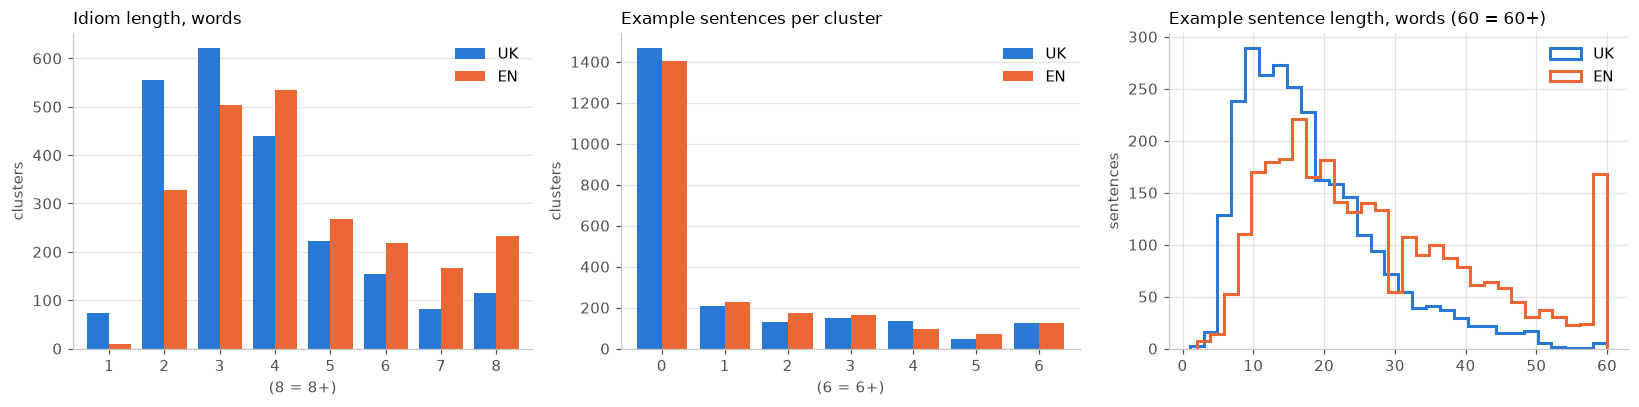

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

for ax, col, title, cap in [(axes[0], "idiom_words", "Idiom length, words", 8),
                            (axes[1], "n_examples", "Example sentences per cluster", 6)]:
    t = (sim_long.assign(v=sim_long[col].clip(upper=cap))
                 .pivot_table(index="v", columns="lang", values="cluster_id", aggfunc="count")
                 .fillna(0))
    t[["uk", "en"]].plot.bar(ax=ax, color=[BLUE, ORANGE], width=0.8, rot=0)
    ax.set(title=title, xlabel=f"({cap} = {cap}+)", ylabel="clusters")
    ax.grid(axis="x", visible=False)
    ax.legend(["UK", "EN"])

ex = sim_long.explode("example_words").dropna(subset=["example_words"])
for lang, c in [("uk", BLUE), ("en", ORANGE)]:
    words = ex.loc[ex.lang == lang, "example_words"].astype(int).clip(upper=60)
    axes[2].hist(words, bins=30, histtype="step", linewidth=2, color=c, label=lang.upper())
axes[2].set(title="Example sentence length, words (60 = 60+)", ylabel="sentences")
axes[2].legend()

fig.tight_layout()
plt.show()

In [21]:
judge["model_name"] = judge["file"].str.rsplit("_", n=3).str[0]
judge["direction"] = judge["lang"]
judge.groupby(["model_name", "direction"]).size().unstack()

direction,en_to_uk,uk_to_en
model_name,,
Qwen3-30B-A3B,5766,5474
claude-haiku-4-5-20251001,5724,5474
gemini-2.5-flash,4781,4796
gemma-3-12b-it,5764,5470
lapa-v0.1.2-instruct,5761,5474
tiny-aya-base,5769,5470


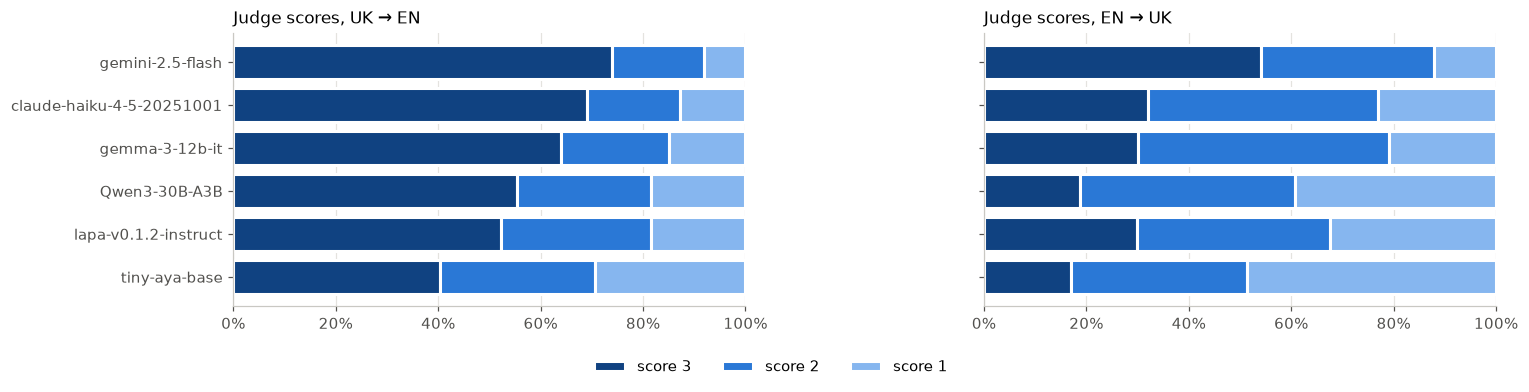

In [22]:
order = judge[judge.direction == "uk_to_en"].groupby("model_name").score.mean().sort_values().index
share = judge.groupby(["direction", "model_name"]).score.value_counts(normalize=True).unstack().fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for ax, d in zip(axes, ["uk_to_en", "en_to_uk"]):
    t = share.loc[d].reindex(order)
    left = pd.Series(0.0, index=t.index)
    for s in [3, 2, 1]:
        ax.barh(t.index, t[s], left=left, color=SCORE_COLORS[s], edgecolor="white", linewidth=2, label=f"score {s}")
        left += t[s]
    ax.set(title=f"Judge scores, {d[:2].upper()} → {d[-2:].upper()}", xlim=(0, 1))
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.grid(axis="y", visible=False)
axes[0].legend(loc="lower center", bbox_to_anchor=(1.05, -0.3), ncol=3)
fig.tight_layout()
plt.show()

In [23]:
judge.pivot_table(index="model_name", columns=["direction", "prompt_type"],
                  values="score", aggfunc="mean").round(2)

direction                 en_to_uk              uk_to_en             
prompt_type                default with context  default with context
model_name                                                           
Qwen3-30B-A3B                 1.78         1.81     2.28         2.46
claude-haiku-4-5-20251001     2.04         2.14     2.45         2.67
gemini-2.5-flash              2.34         2.50     2.59         2.73
gemma-3-12b-it                2.03         2.16     2.37         2.61
lapa-v0.1.2-instruct          1.98         1.98     2.32         2.36
tiny-aya-base                 1.69         1.68     2.06         2.16

In [24]:
(judge[judge.direction == "uk_to_en"]
   .groupby(["cluster_id", "ukrainian_idiom"]).score.agg(["mean", "size"])
   .query("size >= 10").sort_values("mean").head(15).round(2))

,,mean,size
cluster_id,ukrainian_idiom,,
SIM-547,На чужий коровай очей не поривай; На чужий коровай рота не роззявляй,1.00,24
SIM-870,Відверта розмова,1.00,20
SIM-804,Суха ложка рот дере,1.00,10
SIM-1212,Справа провалилася,1.00,24
SIM-281,Не піддавати сумніву; Приймати щось як саме собою зрозуміле; риймати щось за належне,1.00,12
SIM-1322,Почуття ліктя,1.00,12
SIM-1806,Без задніх ніг,1.11,36
SIM-219,Ні сіло ні впало,1.12,48
SIM-2225,Тільки за смертю посилати,1.12,24


## MAGPIE

In [15]:
MAG_REV = "7fa677b82b9a772dfa54bbdd0fb414412d73db3b"
mag_path = fetch(f"https://raw.githubusercontent.com/hslh/magpie-corpus/{MAG_REV}/MAGPIE_filtered_split_random.jsonl",
                 RAW / "magpie" / "MAGPIE_filtered_split_random.jsonl")
magpie = pd.read_json(mag_path, lines=True)
magpie.shape, magpie["label"].value_counts()

✓ magpie/MAGPIE_filtered_split_random.jsonl  (46.9 MB)


((48395, 14),
 label
 i    36328
 l    12067
 Name: count, dtype: int64)

### eda

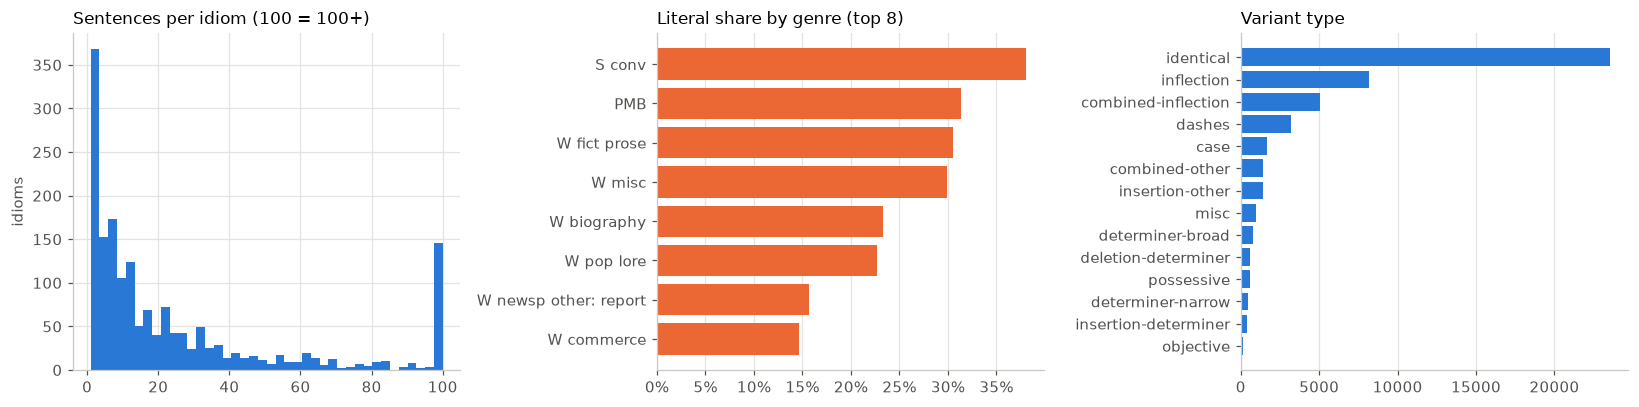

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

per_idiom = magpie.groupby("idiom").size()
axes[0].hist(per_idiom.clip(upper=100), bins=40, color=BLUE)
axes[0].set(title="Sentences per idiom (100 = 100+)", ylabel="idioms")

g = (pd.crosstab(magpie.genre, magpie.label, normalize="index")
       .assign(n=magpie.genre.value_counts()).nlargest(8, "n").sort_values("l"))
axes[1].barh(g.index, g["l"], color=ORANGE)
axes[1].set_title("Literal share by genre (top 8)")
axes[1].xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
axes[1].grid(axis="y", visible=False)

v = magpie.variant_type.value_counts().sort_values()
axes[2].barh(v.index, v.values, color=BLUE)
axes[2].set_title("Variant type")
axes[2].grid(axis="y", visible=False)

fig.tight_layout()
plt.show()

In [26]:
amb = magpie.groupby("idiom").label.agg(n="size", literal_share=lambda s: (s == "l").mean())
amb.query("n >= 30 and 0.3 <= literal_share <= 0.7").sort_values("n", ascending=False).head(15).round(2)

,n,literal_share
idiom,,
behind bars,154,0.53
over the top,143,0.66
get the picture,134,0.66
green light,133,0.40
behind someone's back,126,0.57
point the finger,121,0.32
under the sun,119,0.48
at the crossroads,109,0.60
on ice,108,0.65


## Kobza

In [16]:
from datasets import load_dataset

N = 10_000
kobza_path = RAW / "kobza" / f"kobza_first_{N}.parquet"
if not kobza_path.exists():
    ds = load_dataset("Goader/kobza", split="train", streaming=True,
                      revision="5ec24e168e06ed0e7e0ef70fd734f610ac9ebf93")
    kobza_path.parent.mkdir(parents=True, exist_ok=True)
    pd.DataFrame(list(islice(ds, N))).to_parquet(kobza_path)

kobza = pd.read_parquet(kobza_path)
kobza["source"].value_counts()

source
fineweb-2         3340
hplt-2.0          2665
cultura-x         2584
ukrainian-news     744
ubertext2.0        667
Name: count, dtype: int64

### eda

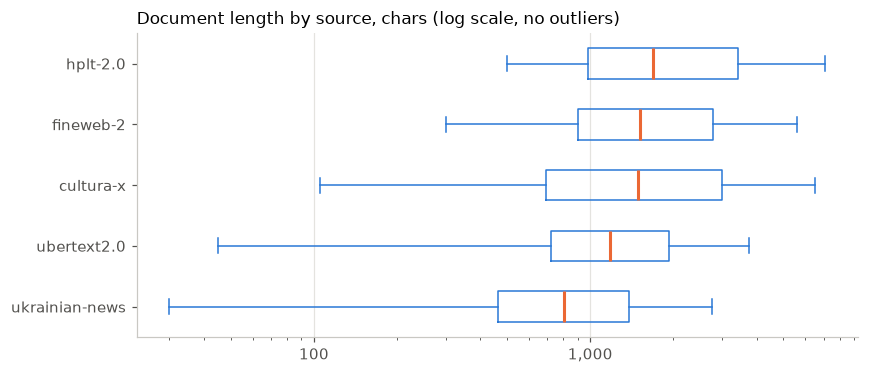

subsource
mC4                1714
news                469
OSCAR-2109          392
OSCAR-2019          323
CC-MAIN-2023-50     162
CC-MAIN-2024-10     139
CC-MAIN-2024-18     135
wikipedia           119
CC-MAIN-2023-40     114
CC-MAIN-2023-23     103
Name: count, dtype: int64

In [27]:
kobza["chars"] = kobza.text.str.len()
order = kobza.groupby("source").chars.median().sort_values().index

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.boxplot([kobza.loc[kobza.source == s, "chars"] for s in order], tick_labels=order,
           orientation="horizontal", showfliers=False,
           medianprops=dict(color=ORANGE, linewidth=2), boxprops=dict(color=BLUE),
           whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE))
ax.set_xscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.set_title("Document length by source, chars (log scale, no outliers)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

kobza.subsource.value_counts().head(10)